Begin Our PySpark Session.

In [1]:
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder.appName("Data Cleaning Curated 2")
    .config("spark.sql.repl.eagerEval.enabled", True)
    .config("spark.sql.parquet.cacheMetadata", "true")
    .config("spark.sql.session.timeZone", "Etc/UTC")
    .config('spark.driver.memory', '8g')
    .config('spark.executor.memory', '4g')
    .getOrCreate()
)
# Silence any WARN-level logs from this point forth.
spark.sparkContext.setLogLevel("ERROR")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/17 23:45:32 WARN Utils: Your hostname, DESKTOP-9UAA9AK, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/17 23:45:32 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/17 23:45:33 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
from functools import reduce

def null_check(df):
    has_null_condition = reduce(
        lambda acc, c: acc | F.col(c).isNull(),
        df.columns,
        F.lit(False)
    )

    # Count total rows, rows with atleast one null and count how many nulls occur
    # per data field.
    summary = df.agg(
        F.count(F.lit(1)).alias("total_rows"),
        F.sum(has_null_condition.cast("int")).alias(
            "rows_with_at_least_one_null"),
        *[F.sum(F.col(c).isNull().cast("int")).alias(
            f"null_{c}") for c in df.columns]
    ).collect()[0]
    
    total = summary["total_rows"]
    rows_with_at_least_one_null = summary["rows_with_at_least_one_null"]
    
    print(f"Total rows: {total:,}")
    print(f"Rows with at least one null value: {rows_with_at_least_one_null:,}")
    print(f"Percentage of rows with atleast one NULL: {round(
        100 * rows_with_at_least_one_null / total, 2)}%")
    print()
    for c in df.columns:
        print(f"{c:25s} {summary[f'null_{c}']:>12,}")

<br>
<br>
<br>

### Dealing with Non-Residential Buildings

In [3]:
curated_one_path = "../../rea_data/curated/vic_rentals_curated_1.parquet"

df_curated_one = spark.read.parquet(curated_one_path)

The assignment brief asks us to predict rents for residential properties and apartments, and to find liveable, affordable suburbs. Things like a car space, Vacant land *etc.* isn't somewhere anyone lives, so it doesn't belong in those answers. 

So we should investigate the different `property_type`'s that appear in this data set and remove those that are irrelevant.

In [4]:
# What property types are in the data 
df_curated_one.groupBy("property_type").agg(
    F.count("*").alias("n"),
).orderBy(F.desc("n")).show(50, truncate=False)

+-----------------------------+----+
|property_type                |n   |
+-----------------------------+----+
|House                        |6589|
|Apartment / Unit / Flat      |4516|
|Townhouse                    |1278|
|Studio                       |209 |
|New Apartments / Off the Plan|45  |
|Villa                        |28  |
|Acreage / Semi-Rural         |13  |
|Semi-Detached                |10  |
|New House & Land             |8   |
|Car Space                    |7   |
|Block of Units               |3   |
|Terrace                      |3   |
|Duplex                       |3   |
|Farm                         |2   |
|Unknown                      |2   |
|Vacant land                  |1   |
+-----------------------------+----+



So, only Car Space (7), Vacant land (1) and Unknown (2) need to go. Everything else is somewhere people can live.

In [5]:
non_residential_types = ["Car Space", "Vacant land", "Unknown"]

n_before = df_curated_one.count()

non_res = df_curated_one.filter(
    F.col("property_type").isin(non_residential_types))
print(f"Non-residential listings removed: {non_res.count():,}")


df_curated_one = df_curated_one.filter(~F.col("property_type").isin(
    non_residential_types)).cache()
print(f"Remaining: {df_curated_one.count():,} \
      "f"({round(100 * non_res.count() / n_before, 2)}%)")

Non-residential listings removed: 10


Remaining: 12,707       (0.08%)


<br>
<br>
<br>

### Dealing with `weekly_rent` 

Seeing as though `weekly_rent` is our **response variable** (the variable we wish to predict), we must ensure that it contains valid values. Since this is the variable we are trying to predict, missing or invalid values cannot be imputed and should instead be removed.


In [6]:
null_check(df_curated_one)

Total rows: 12,707
Rows with at least one null value: 12,707
Percentage of rows with atleast one NULL: 100.0%

listing_id                           0
suburb                               0
postcode                             0
weekly_rent                        276
bond                               781
available_date                     135
date_listed                          4
days_listed                          4
bedrooms                           119
bathrooms                           45
carspaces                        1,800
property_type                        0
address                            104
lat                                  4
lon                                  4
scraped_date                         0
domain_page_id                       1
property_id                     10,139
photo_count                          4
video_count                          4
floorplans_count                     4
virtual_tour                         4
primary_type                   

Firstly, evident by the previous cell's `null_check`, lets remove all 276 rows where `weekly_rent` is `NULL`

In [7]:
# Drop listings with no weekly_rent (null values)
n_before = df_curated_one.count()

df_curated_one = df_curated_one.filter(F.col("weekly_rent").isNotNull())

n_after = df_curated_one.count()
print(f"Rows before: {n_before:,}")
print(f"Rows after:  {n_after:,}")
print(f"Dropped {n_before - n_after:,} listings with NULL weekly_rent "
      f"({round(100 * (n_before - n_after) / n_before, 2)}%)")

Rows before: 12,707
Rows after:  12,431
Dropped 276 listings with NULL weekly_rent (2.17%)


Furthermore, lets do an analysis on `weekly_rent` values to see which values are plausabile and which are not. This could be as a result of misinputs, bad parsing *etc.*

In [8]:
df_curated_one.agg(
    F.min("weekly_rent").alias("min"),
    F.round(F.mean("weekly_rent"), 2).alias("mean"),
    F.max("weekly_rent").alias("max"),
).show()

+---+-----+--------+
|min| mean|     max|
+---+-----+--------+
|0.0|765.1|808500.0|
+---+-----+--------+



In [9]:
print("=== Top 10 highest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.desc("weekly_rent")).show(10)

print("=== Top 10 lowest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.asc("weekly_rent")).show(10)

=== Top 10 highest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  17697966|   808500.0|
|  17750082|   595000.0|
|  17747509|   315000.0|
|  17712191|    10000.0|
|  17661725|     5866.0|
|  17722803|     5750.0|
|   9287841|     5000.0|
|  17744678|     4500.0|
|  17694334|     4500.0|
|  17460975|     4000.0|
+----------+-----------+
only showing top 10 rows
=== Top 10 lowest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  17175722|        0.0|
|  17316329|        0.0|
|  17442602|        0.0|
|  17159699|        0.0|
|  10344261|        0.0|
|  17456126|        0.0|
|  16697431|        0.0|
|  16706257|        0.0|
|  17416575|        0.0|
|  15367349|        0.0|
+----------+-----------+
only showing top 10 rows


First and foremost, its easy to see that the 3 highest weekly rents are most certainly incorrect; most likely the price of the given house/apartment rather than the `weekly_rent`, so we should remove these accordingly. Likewise, any `weekly_rent` that is $=0$ (for whatever reason it may be) is certainly invalid and should also be removed.

Note: As shown by this web page, https://www.domain.com.au/toorak-vic-3142-17712191, the listing with a `weekly_rent` of \$10,000 was found to be a legitimate price.

And so we proceed with said filtering in the following cell:

In [10]:
# --- Remove confirmed misparsed rents (sale prices / concatenated digits) 
# and $0 placeholders ---
misparsed_ids = [17697966, 17750082, 17747509] # $808,500 / $595,000 / $315,000

n_before = df_curated_one.count()

n_misparsed = df_curated_one.filter(
    F.col("listing_id").isin(misparsed_ids)).count()
n_zero = df_curated_one.filter(F.col("weekly_rent") == 0).count()

df_curated_one = df_curated_one.filter(
    ~F.col("listing_id").isin(misparsed_ids) & (F.col("weekly_rent") > 0)
)

n_after = df_curated_one.count()
print(f"Removed {n_misparsed} unreasonably high rents")
print(f"Removed {n_zero} listings with weekly_rent = 0")
print(f"Rows: {n_before:,} -> {n_after:,}")

Removed 3 unreasonably high rents
Removed 17 listings with weekly_rent = 0
Rows: 12,431 -> 12,411


In [11]:
df_curated_one.agg(
    F.min("weekly_rent").alias("min"),
    F.round(F.mean("weekly_rent"), 2).alias("mean"),
    F.max("weekly_rent").alias("max"),
).show()

print("=== Top 10 highest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.desc("weekly_rent")).show(10)

print("=== Top 10 lowest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.asc("weekly_rent")).show(10)

+----+------+-------+
| min|  mean|    max|
+----+------+-------+
|18.0|627.87|10000.0|
+----+------+-------+

=== Top 10 highest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  17712191|    10000.0|
|  17661725|     5866.0|
|  17722803|     5750.0|
|   9287841|     5000.0|
|  17694334|     4500.0|
|  17744678|     4500.0|
|  17460975|     4000.0|
|  17750966|     4000.0|
|  14253235|     3900.0|
|  17721041|     3850.0|
+----------+-----------+
only showing top 10 rows
=== Top 10 lowest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  13243113|       18.0|
|  12352715|       22.0|
|  16490695|       27.0|
|  12981625|       30.0|
|  12981632|       30.0|
|  16559047|       33.0|
|  10801345|       33.0|
|  12853814|       36.0|
|  17240713|       42.0|
|  16211673|       46.0|
+----------+-----------+
only showing top 10 rows


#### Outlier treatment for `weekly_rent`

Lets now flag outliers using IQR fences on log(weekly_rent), with a multiplier that grows
with sample size, k = √(ln N) − 0.5. With N = 12,411
this gives k = 2.57. On the log scale the distribution is roughly symmetric.

- **Lower fence: $203/week** 86 listings flagged.
  
- **Upper fence: $1,663/week** 137 listings flagged.

**We treat the two tails differently.**

*Low outliers (removed).* Rents below about $200/week are implausible for a
self-contained residential lease in Victoria from our outlier analysis.

*High outliers (kept).* High rents are a genuine part of the Victorian rental market,
not data errors. The flagged listings are concentrated in premium suburbs such as
[Toorak, Brighton, South Yarra, …]. They are mostly large houses
and their bonds are consistent with the advertised rent.
Removing the remaining high-end listings would:

1. Understate rents in premium suburbs, where the model would have little data to learn from.
2. Distort the feature-importance question, since features associated with luxury
   properties (pools, tennis courts, city views) would be underrepresented.
3. Bias the growth-rate and affordability analysis, which should cover the full
   market, not a truncated version of it.

Modelling log(weekly_rent) also reduces the influence of these high values on the
fit, so keeping them does not let a few listings dominate the model.

In [12]:
import math

# --- IQR fences with a sample-size-adjusted multiplier ---
df_iqr = df_curated_one.withColumn("log_rent", F.log("weekly_rent"))

N = df_iqr.count()
k = math.sqrt(math.log(N)) - 0.5

q1, q3 = df_iqr.approxQuantile("log_rent", [0.25, 0.75], 0.0)
iqr = q3 - q1
lower_fence = q1 - k * iqr
upper_fence = q3 + k * iqr

print(f"N = {N:,}")
print(f"k = sqrt(ln N) - 0.5 = {k:.3f}")
print(f"Q1 = ${math.exp(q1):,.0f}, Q3 = ${math.exp(q3):,.0f}")
print(f"Lower fence = ${math.exp(lower_fence):,.0f} / week")
print(f"Upper fence = ${math.exp(upper_fence):,.0f} / week")

df_iqr = df_iqr.withColumn(
    "iqr_flag",
    F.when(F.col("log_rent") < lower_fence, F.lit("low_outlier"))
     .when(F.col("log_rent") > upper_fence, F.lit("high_outlier"))
     .otherwise(F.lit("ok"))
)

df_iqr.groupBy("iqr_flag").count().show()

N = 12,411
k = sqrt(ln N) - 0.5 = 2.570
Q1 = $490, Q3 = $690
Lower fence = $203 / week
Upper fence = $1,663 / week
+------------+-----+
|    iqr_flag|count|
+------------+-----+
|high_outlier|  137|
|          ok|12188|
| low_outlier|   86|
+------------+-----+



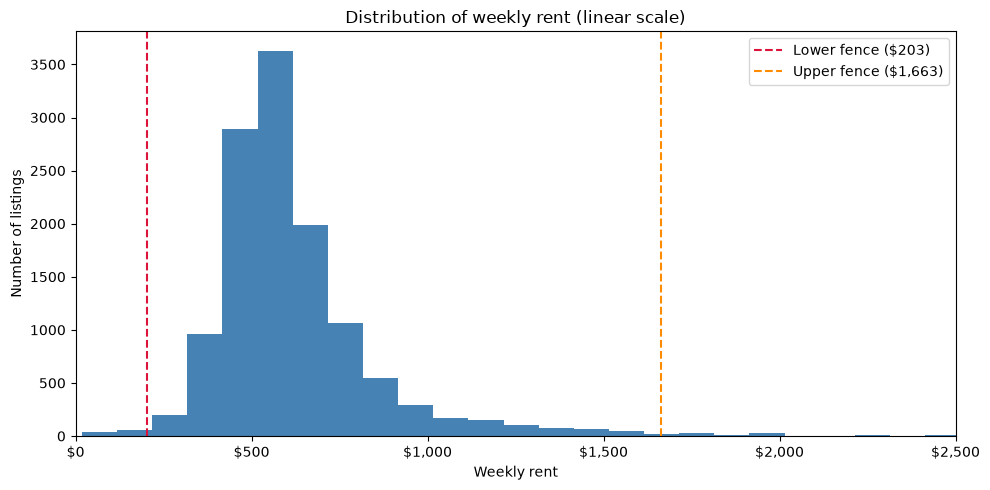

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

rent = df_iqr.select("weekly_rent").toPandas()["weekly_rent"]

# Fences were computed in log space (Cell 1) — convert back to dollars
lower_fence_dollar = math.exp(lower_fence)
upper_fence_dollar = math.exp(upper_fence)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(rent, bins=100, color="steelblue", edgecolor="none")

ax.axvline(lower_fence_dollar, color="crimson", ls="--", lw=1.5,
           label=f"Lower fence (${lower_fence_dollar:,.0f})")
ax.axvline(upper_fence_dollar, color="darkorange", ls="--", lw=1.5,
           label=f"Upper fence (${upper_fence_dollar:,.0f})")

ax.set_xlim(0, 2500)

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))

ax.set_title("Distribution of weekly rent (linear scale)")
ax.set_xlabel("Weekly rent")
ax.set_ylabel("Number of listings")
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
import math

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

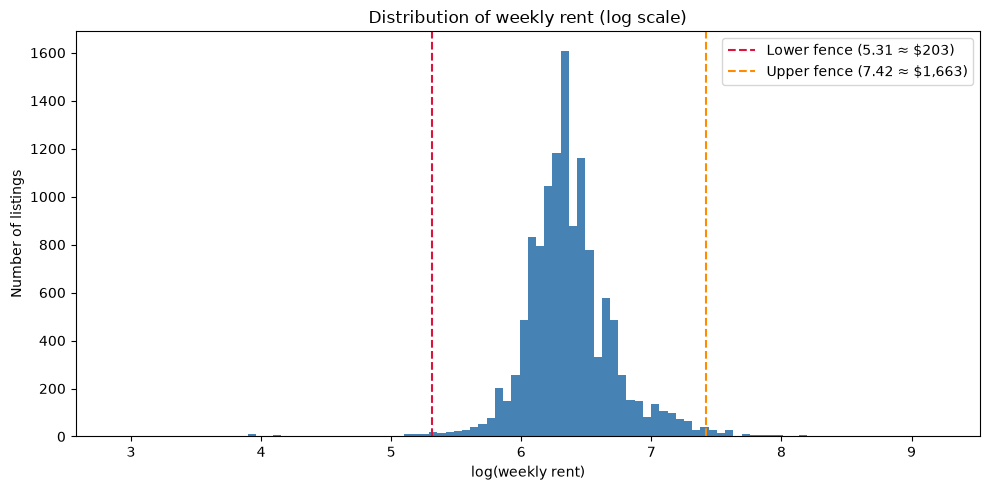

In [15]:
log_rent = np.log(rent)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(log_rent, bins=100, color="steelblue", edgecolor="none")

# Fences are already in log space, so plot them as they are.
ax.axvline(lower_fence, color="crimson", ls="--", lw=1.5,
           label=f"Lower fence ({lower_fence:.2f} ≈ "
                 f"${lower_fence_dollar:,.0f})")
ax.axvline(upper_fence, color="darkorange", ls="--", lw=1.5,
           label=f"Upper fence ({upper_fence:.2f} ≈ "
                 f"${upper_fence_dollar:,.0f})")

ax.set_title("Distribution of weekly rent (log scale)")
ax.set_xlabel("log(weekly rent)")
ax.set_ylabel("Number of listings")
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
review_cols = ["listing_id", "suburb", "primary_type", "bedrooms", 
               "weekly_rent", "url"]

print("=== Low outliers ===")
df_iqr.filter(F.col("iqr_flag") == "low_outlier").select(review_cols) \
    .orderBy("weekly_rent").show(100, vertical=True, truncate=False)

print("=== High outliers ===")
df_iqr.filter(F.col("iqr_flag") == "high_outlier").select(review_cols) \
    .orderBy(F.desc("weekly_rent")).show(100, vertical=True, truncate=False)

=== Low outliers ===
-RECORD 0---------------------------------------------------------------------------------------------------
 listing_id   | 13243113                                                                                    
 suburb       | TONGALA                                                                                     
 primary_type | House                                                                                       
 bedrooms     | NULL                                                                                        
 weekly_rent  | 18.0                                                                                        
 url          | https://www.domain.com.au/5-greiner-court-tongala-vic-3621-13243113                         
-RECORD 1---------------------------------------------------------------------------------------------------
 listing_id   | 12352715                                                                                   

And so, let us **remove** the 86 low end outliers now.

In [17]:
# Remove low-end rent outliers (below the lower IQR fence)
n_before = df_curated_one.count()

df_curated_one = df_curated_one.filter(F.log("weekly_rent") >= lower_fence)

n_after = df_curated_one.count()
print(f"Removed {n_before - n_after} low-end outliers "
      f"(weekly_rent < ${math.exp(lower_fence):,.0f}/week)")
print(f"Rows: {n_before:,} -> {n_after:,}")

Removed 86 low-end outliers (weekly_rent < $203/week)
Rows: 12,411 -> 12,325


Furthermore, lets manually investigate particularly high outlier `weekly_rent` values to ensure they are legitimate.

/tmp/ipykernel_9869/3997379847.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(high_rents, vert=True, widths=0.4, showfliers=False)


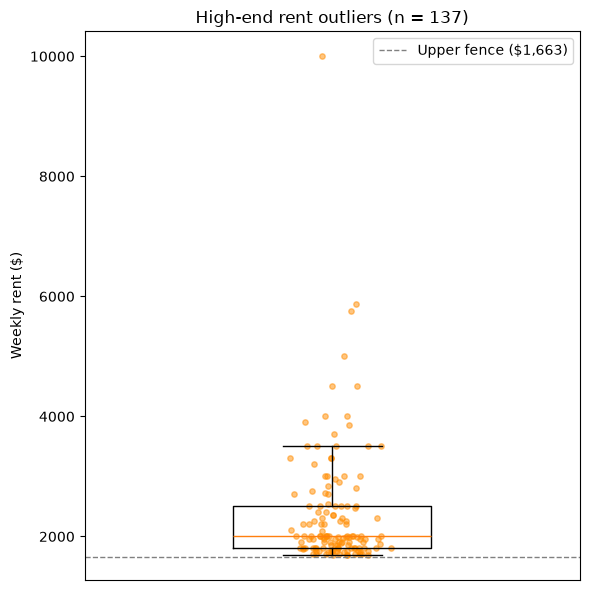

In [18]:
import numpy as np
import matplotlib.pyplot as plt

high_rents = df_iqr.filter(F.col("iqr_flag") == "high_outlier") \
    .select("weekly_rent").toPandas()["weekly_rent"]

fig, ax = plt.subplots(figsize=(6, 6))

ax.boxplot(high_rents, vert=True, widths=0.4, showfliers=False)

# Each listing as a jittered dot, so you can see how they spread
jitter = np.random.normal(1, 0.04, size=len(high_rents))
ax.scatter(jitter, high_rents, alpha=0.5, s=15, color="darkorange")

ax.axhline(np.exp(upper_fence), color="grey", ls="--", lw=1,
           label=f"Upper fence (${np.exp(upper_fence):,.0f})")

ax.set_title(f"High-end rent outliers (n = {len(high_rents)})")
ax.set_ylabel("Weekly rent ($)")
ax.set_xticks([])
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
high_pdf = df_iqr.filter(F.col("iqr_flag") == "high_outlier") \
    .select("listing_id", "suburb", "primary_type", "bedrooms",
            "weekly_rent", "bond", "url").toPandas()

q1_h, q3_h = high_pdf["weekly_rent"].quantile([0.25, 0.75])
whisker = q3_h + 1.5 * (q3_h - q1_h)

above = high_pdf[high_pdf["weekly_rent"] > whisker] \
    .sort_values("weekly_rent", ascending=False)

print(f"Upper whisker within high outliers: ${whisker:,.0f}/week")
print(f"Listings above it: {len(above)}")
above

Upper whisker within high outliers: $3,550/week
Listings above it: 11


,listing_id,suburb,primary_type,bedrooms,weekly_rent,bond,url
87,17712191,TOORAK,House,6.0,10000.0,60000.0,https://www.domain.com.au/toorak-vic-3142-1771...
113,17661725,CAMBERWELL,House,5.0,5866.0,5866.0,https://www.domain.com.au/54-fairmont-avenue-c...
88,17722803,TOORAK,House,4.0,5750.0,34500.0,https://www.domain.com.au/2-lisbuoy-court-toor...
129,9287841,BRIGHTON,Apartment,5.0,5000.0,NaN,https://www.domain.com.au/brighton-vic-3186-92...
99,17694334,SOUTH YARRA,Apartment,3.0,4500.0,27000.0,https://www.domain.com.au/1-fairlie-court-sout...
67,17744678,HAWTHORN,House,5.0,4500.0,27000.0,https://www.domain.com.au/94-illawarra-road-ha...
5,17460975,SOUTH MELBOURNE,Apartment,4.0,4000.0,24000.0,https://www.domain.com.au/901-161-eastern-road...
119,17750966,BRIGHTON,House,4.0,4000.0,24000.0,https://www.domain.com.au/74-champion-street-b...
9,14253235,PORT MELBOURNE,Townhouse/Villa,4.0,3900.0,23400.0,https://www.domain.com.au/1-tarver-st-port-mel...
26,17721041,CREMORNE,House,4.0,3850.0,15400.0,https://www.domain.com.au/13-balmain-st-cremor...


Upon our manual inspection of every high-end listing above the box-plot whisker (done by serching the property listing online), we find that `listing_id` = 17661725 is the only listing that has a false `weekly_rent` value. Since its true `weekly_rent` cannon't reliably be infered we will remove this row aswell.

In [20]:
# --- Remove a high-end listing confirmed as misparsed after manual review ---
n_before = df_curated_one.count()

HIGH_END_LISTING_FALSE = 17661725

df_curated_one = df_curated_one.filter(
    F.col("listing_id") != HIGH_END_LISTING_FALSE)

print(f"Removed {n_before - df_curated_one.count()} listing \
      (listing_id = 17661725)")
print(f"Rows: {n_before:,} -> {df_curated_one.count():,}")

Removed 1 listing       (listing_id = 17661725)
Rows: 12,325 -> 12,324


Lets persist what we have done for `weekly_values` and Non-Residential buildings for ease of use for further data cleaning.

In [21]:
# Save the cleaned DataFrame to Parquet format
output_path = "../../rea_data/curated/vic_rentals_curated_2.parquet"

df_curated_one.write.mode("overwrite").parquet(output_path)

print(f"Shape: {df_curated_one.count():,} rows, \
      {len(df_curated_one.columns)} columns")

Shape: 12,324 rows,       84 columns


<br>
<br>
<br>

### Dealing with `date_listed`

In [22]:
curated_two_path = "../../rea_data/curated/vic_rentals_curated_2.parquet"

df_curated_two = spark.read.parquet(curated_two_path)

`date_listed` is very obviously important to our project so lets clean this column for missing or invalid values.

Lets begin by checking for any `NULL` values.

In [23]:
null_check(df_curated_two)

Total rows: 12,324
Rows with at least one null value: 12,324
Percentage of rows with atleast one NULL: 100.0%

listing_id                           0
suburb                               0
postcode                             0
weekly_rent                          0
bond                               738
available_date                       4
date_listed                          4
days_listed                          4
bedrooms                            76
bathrooms                            8
carspaces                        1,704
property_type                        0
address                             87
lat                                  4
lon                                  4
scraped_date                         0
domain_page_id                       1
property_id                     10,006
photo_count                          4
video_count                          4
floorplans_count                     4
virtual_tour                         4
primary_type                   

There are 4 values where `date_listed` = `NULL` so lets remove these.

In [24]:
# Drop listings with no date_listed 
n_before = df_curated_two.count()

df_curated_two = df_curated_two.filter(F.col("date_listed").isNotNull())

n_after = df_curated_two.count()
print(f"Removed {n_before - n_after} listings with NULL date_listed")
print(f"Rows: {n_before:,} -> {n_after:,}")

Removed 4 listings with NULL date_listed
Rows: 12,324 -> 12,320


Now lets check that all non-null `date_listed` values parse as valid dates (`yyyy-MM-dd`).

The older listings will be kept for time-series modelling.

In [25]:
df_curated_two.select(
    F.sum(
        (F.col("date_listed").isNotNull() &
         F.to_date(F.col("date_listed").cast(
             "string"), "yyyy-MM-dd").isNull()).cast("int")
    ).alias("unparseable"),
    F.min("date_listed").alias("earliest"),
    F.max("date_listed").alias("latest"),
).show()

+-----------+----------+----------+
|unparseable|  earliest|    latest|
+-----------+----------+----------+
|          0|2012-06-09|2025-09-09|
+-----------+----------+----------+



All non-null `date_listed` values parse as valid dates (`yyyy-MM-dd`), ranging from 9 June 2012 to 9 September 2025, the scrape date, so no values are malformed or in the future.

Since we hope to create a time series model with our data, lets feature engineer a `listed_month` and `listed_year` column to indicate, obviously, what month and year a property was listed.

In [26]:
# Extract year and month from date_listed 
df_curated_two = (
    df_curated_two
    .withColumn("date_listed", F.to_date("date_listed"))
    .withColumn("listed_year", F.year("date_listed"))
    .withColumn("listed_month", F.month("date_listed"))
)

df_curated_two.select("date_listed", "listed_year", "listed_month").show(1, 
                            vertical=True)

-RECORD 0------------------
 date_listed  | 2025-08-13 
 listed_year  | 2025       
 listed_month | 8          
only showing top 1 row


In [27]:
# Export the final cleaned DataFrame
final_path = "../../rea_data/curated/vic_rentals_curated_3.parquet"

df_curated_two.write.mode("overwrite").parquet(final_path)

# Sanity check: read back and confirm shape
df_check = spark.read.parquet(final_path)
print(f"Saved to: {final_path}")
print(f"Shape: {df_check.count():,} rows, {len(df_check.columns)} columns")

Saved to: ../../rea_data/curated/vic_rentals_curated_3.parquet
Shape: 12,320 rows, 86 columns
